# CDS 3301 Machine Learning - Individual Assignment

## Part C: Machine Learning Implementation

### C1. Diabetes Regression

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [23]:
diabetes = load_diabetes()

X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y = pd.Series(diabetes.target, name="target")

print("Dataset loaded successfully!")
print("Features:", X.shape)
print("Target:", y.shape)

Dataset loaded successfully!
Features: (442, 10)
Target: (442,)


In [24]:
X.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [25]:
X.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01


In [26]:
print("Missing values in each feature:")
print(X.isnull().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

Missing values in each feature:
age    0
sex    0
bmi    0
bp     0
s1     0
s2     0
s3     0
s4     0
s5     0
s6     0
dtype: int64

Missing values in target:
0


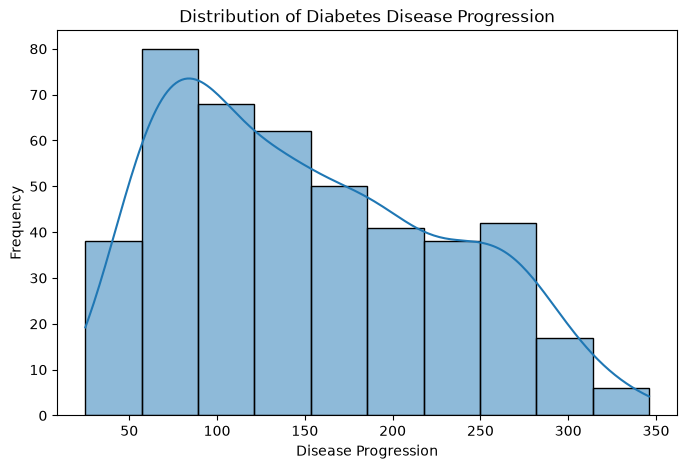

In [27]:
plt.figure(figsize=(8, 5))

sns.histplot(y, kde=True)

plt.title("Distribution of Diabetes Disease Progression")
plt.xlabel("Disease Progression")
plt.ylabel("Frequency")
plt.show()

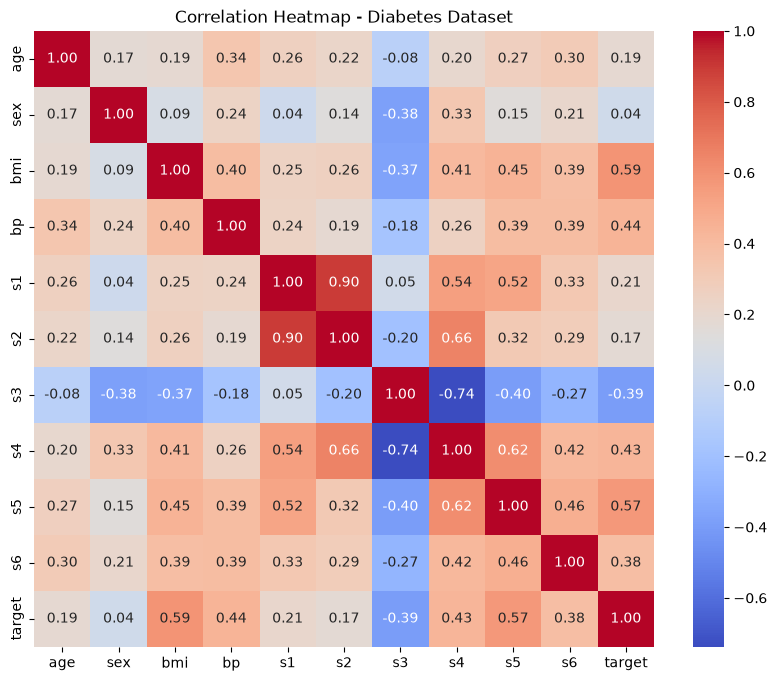

In [28]:
plt.figure(figsize=(10, 8))

correlation_data = pd.concat([X, y], axis=1)

sns.heatmap(
    correlation_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - Diabetes Dataset")
plt.show()

### C1.2 Data Preprocessing and Train-Test Split

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=9386
)

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training data:
X_train: (331, 10)
y_train: (331,)

Testing data:
X_test: (111, 10)
y_test: (111,)


### C1.3 Linear Regression Model

In [30]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [31]:
y_pred_linear

array([194.17947083, 170.7123491 , 222.80756388, 135.9011187 ,
       142.17061231, 215.44445485, 158.08797315, 134.2199616 ,
       103.2904422 ,  53.1019297 , 213.22802516, 144.26815253,
       121.17450805, 159.93140353, 167.32351802, 219.5845444 ,
       234.71380754,  97.66041843, 204.11731728, 149.08151055,
       109.68804263,  57.50662978, 157.53571723, 146.26762645,
       110.06661689, 144.66719147, 119.85034902, 155.44211361,
        82.56871845,  83.99080268, 114.09321849, 288.07983401,
        79.6796114 ,  78.2947469 , 132.04777731, 169.0170169 ,
       136.93333865,  73.76140902, 129.64220538, 183.21036209,
       230.39581287,  82.88136265, 131.86121924, 250.17260028,
       192.24594314, 184.2686197 , 168.20750817, 161.60863316,
       155.2386735 , 226.64190987, 163.20480159, 114.46042777,
       228.63032512, 179.62246812, 163.73809283, 172.03061936,
        76.51607234,  94.61790128,  82.26430446,  93.95628362,
       132.42793818, 165.81514957, 212.23951981, 126.32

### C1.4 Decision Tree Regressor Model

In [32]:
tree_model = DecisionTreeRegressor(
    random_state=9386
)

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

print("Decision Tree Regressor trained successfully.")

Decision Tree Regressor trained successfully.


### C1.5 Model Evaluation

In [33]:
# Linear Regression metrics
linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_rmse = np.sqrt(mean_squared_error(y_test, y_pred_linear))
linear_r2 = r2_score(y_test, y_pred_linear)

# Decision Tree metrics
tree_mae = mean_absolute_error(y_test, y_pred_tree)
tree_rmse = np.sqrt(mean_squared_error(y_test, y_pred_tree))
tree_r2 = r2_score(y_test, y_pred_tree)

# Create comparison table
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree Regressor"
    ],
    "MAE": [
        linear_mae,
        tree_mae
    ],
    "RMSE": [
        linear_rmse,
        tree_rmse
    ],
    "R²": [
        linear_r2,
        tree_r2
    ]
})

results.round(3)

,Model,MAE,RMSE,R²
0,Linear Regression,48.197,57.481,0.399
1,Decision Tree Regressor,68.009,86.403,-0.357


In [34]:
if linear_r2 > tree_r2:
    better_model = "Linear Regression"
    better_predictions = y_pred_linear
else:
    better_model = "Decision Tree Regressor"
    better_predictions = y_pred_tree

print("Better model based on R²:", better_model)

Better model based on R²: Linear Regression


### C1.6 Actual vs Predicted Values

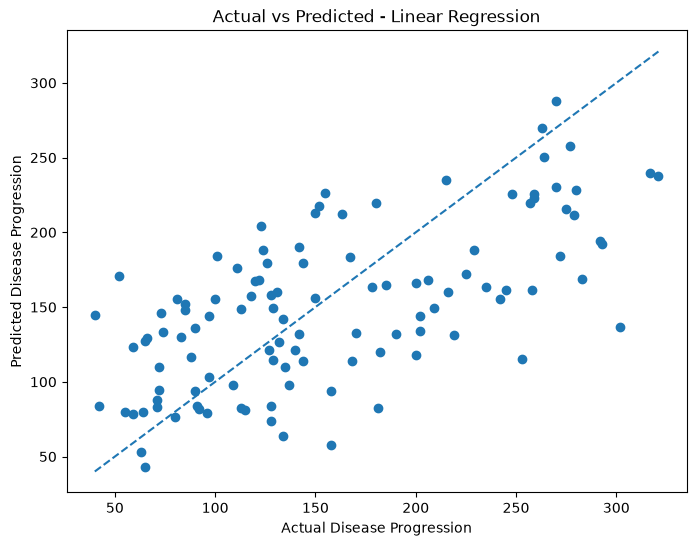

In [35]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, better_predictions)

# Perfect prediction line
min_value = min(y_test.min(), better_predictions.min())
max_value = max(y_test.max(), better_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Disease Progression")
plt.ylabel("Predicted Disease Progression")
plt.title(f"Actual vs Predicted - {better_model}")

plt.show()

### C1.7 Five-Fold Cross-Validation

In [36]:
linear_cv_scores = cross_val_score(
    linear_model,
    X,
    y,
    cv=5,
    scoring="r2"
)

tree_cv_scores = cross_val_score(
    tree_model,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("Linear Regression 5-Fold R² Scores:")
print(linear_cv_scores)

print("\nDecision Tree Regressor 5-Fold R² Scores:")
print(tree_cv_scores)

Linear Regression 5-Fold R² Scores:
[0.42955615 0.52259939 0.48268054 0.42649776 0.55024834]

Decision Tree Regressor 5-Fold R² Scores:
[-0.30264538 -0.04447044  0.03434817  0.08941116 -0.17956175]


In [37]:
linear_cv_mean = linear_cv_scores.mean()
tree_cv_mean = tree_cv_scores.mean()

print("Mean Linear Regression CV R²:", round(linear_cv_mean, 3))
print("Mean Decision Tree CV R²:", round(tree_cv_mean, 3))

Mean Linear Regression CV R²: 0.482
Mean Decision Tree CV R²: -0.081


In [38]:
cv_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree Regressor"
    ],
    "Mean CV R²": [
        linear_cv_mean,
        tree_cv_mean
    ]
})

cv_results.round(3)

,Model,Mean CV R²
0,Linear Regression,0.482
1,Decision Tree Regressor,-0.081


In [39]:
if linear_cv_mean > tree_cv_mean:
    cv_better_model = "Linear Regression"
else:
    cv_better_model = "Decision Tree Regressor"

print("Better model based on mean 5-fold CV R²:", cv_better_model)

Better model based on mean 5-fold CV R²: Linear Regression


In [40]:
print("Mean Linear Regression CV R²:", round(linear_cv_mean, 3))
print("Mean Decision Tree Regressor CV R²:", round(tree_cv_mean, 3))

Mean Linear Regression CV R²: 0.482
Mean Decision Tree Regressor CV R²: -0.081


For the Diabetes regression task, two models were trained and evaluated: Linear Regression and Decision Tree Regressor. Linear Regression achieved an MAE of 48.197, RMSE of 57.481, and R² of 0.399, while the Decision Tree Regressor achieved an MAE of 68.009, RMSE of 86.403, and R² of -0.357. Therefore, Linear Regression produced smaller prediction errors and explained more variation in the target variable.

The 5-fold cross-validation results also favored Linear Regression, with a mean R² of 0.482, compared with -0.081 for the Decision Tree Regressor. The higher cross-validation R² indicates that Linear Regression generalized better across different subsets of the dataset. The negative cross-validation R² of the Decision Tree suggests poor generalization.

Linear Regression was the better-performing model for the Diabetes dataset. Its lower MAE and RMSE, together with its higher test and cross-validation R² values, indicate that it provided more reliable predictions of disease progression than the Decision Tree Regressor.

### C2. Ionosphere Classification

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
#import required libraries

#### C2.1 Loading the Ionosphere Dataset

In [42]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/ionosphere/ionosphere.data"

ionosphere = pd.read_csv(url, header=None)

print("Dataset loaded successfully!")
print("Dataset shape:", ionosphere.shape)

ionosphere.head()
#load the dataset

Dataset loaded successfully!
Dataset shape: (351, 35)


,0,1,2,3,4,5,6,7,8,9,...,25,26,27,28,29,30,31,32,33,34
0,1,0,0.99539,-0.05889,0.85243,0.02306,0.83398,-0.37708,1.00000,0.03760,...,-0.51171,0.41078,-0.46168,0.21266,-0.34090,0.42267,-0.54487,0.18641,-0.45300,g
1,1,0,1.00000,-0.18829,0.93035,-0.36156,-0.10868,-0.93597,1.00000,-0.04549,...,-0.26569,-0.20468,-0.18401,-0.19040,-0.11593,-0.16626,-0.06288,-0.13738,-0.02447,b
2,1,0,1.00000,-0.03365,1.00000,0.00485,1.00000,-0.12062,0.88965,0.01198,...,-0.40220,0.58984,-0.22145,0.43100,-0.17365,0.60436,-0.24180,0.56045,-0.38238,g
3,1,0,1.00000,-0.45161,1.00000,1.00000,0.71216,-1.00000,0.00000,0.00000,...,0.90695,0.51613,1.00000,1.00000,-0.20099,0.25682,1.00000,-0.32382,1.00000,b
4,1,0,1.00000,-0.02401,0.94140,0.06531,0.92106,-0.23255,0.77152,-0.16399,...,-0.65158,0.13290,-0.53206,0.02431,-0.62197,-0.05707,-0.59573,-0.04608,-0.65697,g


In [43]:
print("Number of rows:", ionosphere.shape[0])
print("Number of columns:", ionosphere.shape[1])

ionosphere.info()

ionosphere.head() #examine to check 34 input features, 1 target column

Number of rows: 351
Number of columns: 35
<class 'pandas.DataFrame'>
RangeIndex: 351 entries, 0 to 350
Data columns (total 35 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       351 non-null    int64  
 1   1       351 non-null    int64  
 2   2       351 non-null    float64
 3   3       351 non-null    float64
 4   4       351 non-null    float64
 5   5       351 non-null    float64
 6   6       351 non-null    float64
 7   7       351 non-null    float64
 8   8       351 non-null    float64
 9   9       351 non-null    float64
 10  10      351 non-null    float64
 11  11      351 non-null    float64
 12  12      351 non-null    float64
 13  13      351 non-null    float64
 14  14      351 non-null    float64
 15  15      351 non-null    float64
 16  16      351 non-null    float64
 17  17      351 non-null    float64
 18  18      351 non-null    float64
 19  19      351 non-null    float64
 20  20      351 non-null    float64
 21  21      

,0,1,2,3,4,5,6,7,8,9,...,25,26,27,28,29,30,31,32,33,34
0,1,0,0.99539,-0.05889,0.85243,0.02306,0.83398,-0.37708,1.00000,0.03760,...,-0.51171,0.41078,-0.46168,0.21266,-0.34090,0.42267,-0.54487,0.18641,-0.45300,g
1,1,0,1.00000,-0.18829,0.93035,-0.36156,-0.10868,-0.93597,1.00000,-0.04549,...,-0.26569,-0.20468,-0.18401,-0.19040,-0.11593,-0.16626,-0.06288,-0.13738,-0.02447,b
2,1,0,1.00000,-0.03365,1.00000,0.00485,1.00000,-0.12062,0.88965,0.01198,...,-0.40220,0.58984,-0.22145,0.43100,-0.17365,0.60436,-0.24180,0.56045,-0.38238,g
3,1,0,1.00000,-0.45161,1.00000,1.00000,0.71216,-1.00000,0.00000,0.00000,...,0.90695,0.51613,1.00000,1.00000,-0.20099,0.25682,1.00000,-0.32382,1.00000,b
4,1,0,1.00000,-0.02401,0.94140,0.06531,0.92106,-0.23255,0.77152,-0.16399,...,-0.65158,0.13290,-0.53206,0.02431,-0.62197,-0.05707,-0.59573,-0.04608,-0.65697,g


In [44]:
feature_names = [f"feature_{i}" for i in range(1, 35)]

ionosphere.columns = feature_names + ["target"]

ionosphere.head() #giving the columns meaningful names

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,...,feature_26,feature_27,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33,feature_34,target
0,1,0,0.99539,-0.05889,0.85243,0.02306,0.83398,-0.37708,1.00000,0.03760,...,-0.51171,0.41078,-0.46168,0.21266,-0.34090,0.42267,-0.54487,0.18641,-0.45300,g
1,1,0,1.00000,-0.18829,0.93035,-0.36156,-0.10868,-0.93597,1.00000,-0.04549,...,-0.26569,-0.20468,-0.18401,-0.19040,-0.11593,-0.16626,-0.06288,-0.13738,-0.02447,b
2,1,0,1.00000,-0.03365,1.00000,0.00485,1.00000,-0.12062,0.88965,0.01198,...,-0.40220,0.58984,-0.22145,0.43100,-0.17365,0.60436,-0.24180,0.56045,-0.38238,g
3,1,0,1.00000,-0.45161,1.00000,1.00000,0.71216,-1.00000,0.00000,0.00000,...,0.90695,0.51613,1.00000,1.00000,-0.20099,0.25682,1.00000,-0.32382,1.00000,b
4,1,0,1.00000,-0.02401,0.94140,0.06531,0.92106,-0.23255,0.77152,-0.16399,...,-0.65158,0.13290,-0.53206,0.02431,-0.62197,-0.05707,-0.59573,-0.04608,-0.65697,g


In [ ]:
print("Target classes:")
print(ionosphere["target"].value_counts()) #chech target classes

#calculate their percentages to examine class distribution
class_percentages = (
    ionosphere["target"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Class percentages:")
print(class_percentages)

Target classes:
target
g    225
b    126
Name: count, dtype: int64
Class percentages:
target
g    64.1
b    35.9
Name: proportion, dtype: float64


#### C2.2 Exploratory Data Analysis

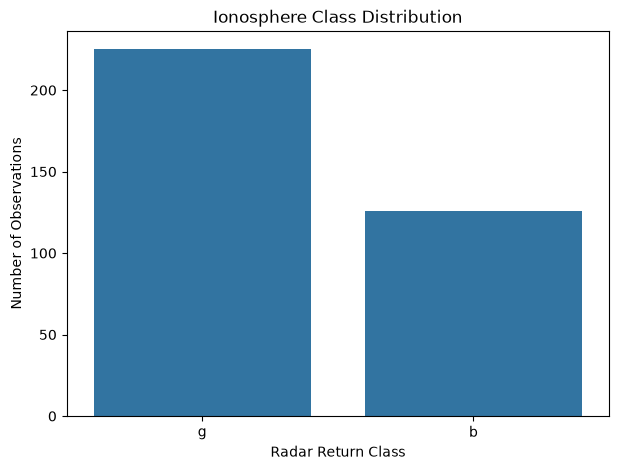

In [46]:
plt.figure(figsize=(7, 5))

sns.countplot(data=ionosphere, x="target")

plt.title("Ionosphere Class Distribution")
plt.xlabel("Radar Return Class")
plt.ylabel("Number of Observations")

plt.show()
#visualize the distribution to see if classes are balanced or imbalanced

In [47]:
print("Missing values in each column:")
print(ionosphere.isnull().sum().sum()) #check for missing values

Missing values in each column:
0


#### C2.3 Data Preparation

In [49]:
X = ionosphere.drop("target", axis=1)
y = ionosphere["target"] #separate features and targets

#convert targets into numbers
y = y.map({"b": 0, "g": 1})

print(y.value_counts())

target
1    225
0    126
Name: count, dtype: int64


###  perform stratified train-test split

In [50]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=9386,
    stratify=y
)

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
#to maintain same proportion of good and bad radar returns

Training data:
X_train: (263, 34)
y_train: (263,)

Testing data:
X_test: (88, 34)
y_test: (88,)


In [51]:
#Verify the stratification
print("Original class distribution:")
print(y.value_counts(normalize=True).round(3))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))

Original class distribution:
target
1    0.641
0    0.359
Name: proportion, dtype: float64

Training class distribution:
target
1    0.643
0    0.357
Name: proportion, dtype: float64

Testing class distribution:
target
1    0.636
0    0.364
Name: proportion, dtype: float64


#### C2.4 Logistic Regression Training

In [52]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=9386
)

logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [ ]:
y_pred_logistic  #model predicted class(0-1)

array([0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1,
       1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1,
       1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1])

In [ ]:
y_prob_logistic 
#predicted probability of class 1 needed for calculating ROC-AUC

array([2.34382304e-01, 9.00556127e-01, 9.49463442e-01, 9.84754895e-01,
       3.81340879e-01, 9.14387917e-01, 8.65186183e-01, 5.45504431e-01,
       9.72882852e-01, 8.40141410e-01, 9.53734613e-01, 9.41679362e-01,
       9.56324236e-01, 8.21838254e-01, 1.76341033e-01, 4.66999315e-01,
       7.84816247e-01, 9.31311849e-01, 9.65890948e-01, 9.38749594e-04,
       7.45518807e-01, 9.00513830e-01, 9.37881348e-01, 7.19235051e-02,
       1.95933330e-01, 8.43612855e-01, 9.57382232e-01, 7.84810311e-01,
       9.38856755e-01, 3.26813298e-02, 5.26828315e-01, 9.38802818e-01,
       9.32101327e-01, 9.15845039e-01, 1.53401806e-01, 4.39788508e-01,
       9.28849373e-01, 7.88409826e-01, 1.41951348e-01, 8.05516337e-01,
       8.59560582e-01, 1.27177062e-01, 9.40839980e-01, 8.03651884e-01,
       9.46258353e-01, 3.18455543e-01, 8.55776170e-01, 4.77541623e-06,
       9.53273019e-01, 9.52355037e-01, 9.28186387e-01, 9.15099496e-01,
       9.78127139e-01, 9.17274260e-01, 2.98527278e-01, 5.98060593e-01,
      

#### C2.5 Random Forest Classifier Training

In [55]:
random_forest = RandomForestClassifier(
    random_state=9386
)

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)
y_prob_rf = random_forest.predict_proba(X_test)[:, 1]

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [56]:
y_pred_rf #contains predicted classes

array([0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1,
       1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1,
       1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1])

In [57]:
y_prob_rf #contains probability needed for ROC-AUC

array([0.05, 0.52, 0.98, 0.83, 0.37, 1.  , 1.  , 0.95, 0.98, 0.48, 0.87,
       0.92, 0.66, 0.2 , 0.07, 0.09, 0.16, 1.  , 1.  , 0.17, 0.98, 0.98,
       1.  , 0.16, 0.08, 0.99, 0.97, 0.99, 1.  , 0.06, 0.52, 0.99, 1.  ,
       0.96, 0.03, 0.81, 0.88, 1.  , 0.05, 0.98, 0.99, 0.06, 0.96, 0.95,
       0.2 , 0.14, 0.99, 0.12, 1.  , 0.91, 0.98, 1.  , 0.98, 0.96, 0.08,
       0.2 , 0.99, 0.97, 0.94, 0.88, 1.  , 0.95, 0.68, 0.23, 0.03, 0.86,
       1.  , 0.1 , 0.06, 0.83, 0.78, 0.99, 0.94, 0.12, 0.04, 0.86, 1.  ,
       0.97, 0.12, 0.94, 0.99, 0.99, 0.91, 0.86, 0.91, 1.  , 0.04, 0.96])

#### C2.6 Model Evaluation (Accuracy, Precision, Recall, F1, ROC-AUC)

In [58]:
# Logistic Regression metrics
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_precision = precision_score(y_test, y_pred_logistic)
logistic_recall = recall_score(y_test, y_pred_logistic)
logistic_f1 = f1_score(y_test, y_pred_logistic)
logistic_roc_auc = roc_auc_score(y_test, y_prob_logistic)

# Random Forest metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

# Create comparison table
classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        rf_accuracy
    ],
    "Precision": [
        logistic_precision,
        rf_precision
    ],
    "Recall": [
        logistic_recall,
        rf_recall
    ],
    "F1": [
        logistic_f1,
        rf_f1
    ],
    "ROC-AUC": [
        logistic_roc_auc,
        rf_roc_auc
    ]
})

classification_results.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.875,0.846,0.982,0.909,0.939
1,Random Forest,0.943,0.918,1.000,0.957,0.966


#### C2.7 Logistic Regression Confusion Matrix

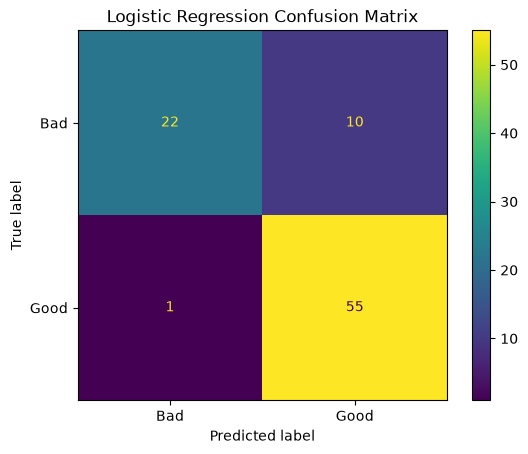

In [59]:
cm_logistic = confusion_matrix(y_test, y_pred_logistic)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=["Bad", "Good"]
)

disp.plot()

plt.title("Logistic Regression Confusion Matrix")
plt.show()

#### C2.8 Random Forest Confusion Matrix

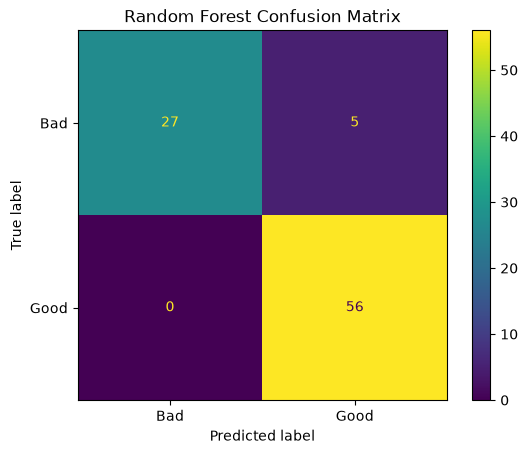

In [60]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Bad", "Good"]
)

disp.plot()

plt.title("Random Forest Confusion Matrix")
plt.show()

#### C2.9 Five-Fold Stratified Cross-Validation

In [ ]:
stratified_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=9386
)

logistic_cv_scores = cross_val_score(
    logistic_model,
    X,
    y,
    cv=stratified_cv,
    scoring="f1"
)

rf_cv_scores = cross_val_score(
    random_forest,
    X,
    y,
    cv=stratified_cv,
    scoring="f1"
)

print("Logistic Regression 5-Fold F1 Scores:")
print(logistic_cv_scores)

print("\nRandom Forest 5-Fold F1 Scores:")
print(rf_cv_scores)
#F1 was the metric we selected in A4 as the most informative metric

Logistic Regression 5-Fold F1 Scores:
[0.92631579 0.88659794 0.93617021 0.91836735 0.85714286]

Random Forest 5-Fold F1 Scores:
[0.96629213 0.92473118 0.96703297 0.93617021 0.95555556]


In [66]:
logistic_cv_mean = logistic_cv_scores.mean()
rf_cv_mean = rf_cv_scores.mean()

print(
    "Mean Logistic Regression 5-Fold F1:",
    round(logistic_cv_mean, 3)
)

print(
    "Mean Random Forest 5-Fold F1:",
    round(rf_cv_mean, 3)
)
#Mean cross validation F1

Mean Logistic Regression 5-Fold F1: 0.905
Mean Random Forest 5-Fold F1: 0.95


In [67]:
#Comparison table
cv_classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Mean 5-Fold F1": [
        logistic_cv_mean,
        rf_cv_mean
    ]
})

cv_classification_results.round(3)

,Model,Mean 5-Fold F1
0,Logistic Regression,0.905
1,Random Forest,0.950


### Model Recommendation

Random Forest is the recommended model for the Ionosphere classification. It achieved a higher F1-score than Logistic Regression on the test set and also obtained a higher mean F1-score during 5-fold stratified cross-validation. Since F1-score balances precision and recall, Random Forest provides the better overall classification performance according to the selected evaluation criterion. The cross-validation results also suggest that its performance was more consistent across different subsets of the data.

### Interpretation

The Random Forest model performed better than Logistic Regression on the Ionosphere dataset. It achieved a higher F1-score on the test data and also had a higher mean F1-score in 5-fold stratified cross-validation. Since F1-score balances precision and recall, Random Forest is the preferred model according to the evaluation criterion selected in Part A4. Its higher cross-validation score also indicates stronger and more consistent performance.

## C3. Wholesale Customers Clustering

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
#Importing libraries

In [73]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"

wholesale = pd.read_csv(url)

wholesale.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [74]:
print("Dataset shape:", wholesale.shape)

print("\nColumn names:")
print(wholesale.columns.tolist())

print("\nData types:")
print(wholesale.dtypes)

print("\nMissing values:")
print(wholesale.isnull().sum())
#Examine the dataset

Dataset shape: (440, 8)

Column names:
['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

Data types:
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object

Missing values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


In [75]:
features = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

X = wholesale[features]

X.head()
#Select the clustering features

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [76]:
print("Clustering data shape:", X.shape)
#Check the dimensions

Clustering data shape: (440, 6)


In [77]:
X.describe()
#Check descriptive statistics

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [78]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features
)

X_scaled.head()
#standardize the data

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


In [79]:
# Run K-Means for k = 2 to 8

inertia_values = []
silhouette_values = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=9386,
        n_init=10
    )
    
    cluster_labels = kmeans.fit_predict(X_scaled)
    
    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled, cluster_labels)
    )

print("Inertia values:")
for k, inertia in zip(range(2, 9), inertia_values):
    print(f"k={k}: {inertia:.3f}")

print("\nSilhouette scores:")
for k, score in zip(range(2, 9), silhouette_values):
    print(f"k={k}: {score:.3f}")

Inertia values:
k=2: 1954.802
k=3: 1620.375
k=4: 1325.844
k=5: 1058.771
k=6: 925.562
k=7: 838.772
k=8: 751.548

Silhouette scores:
k=2: 0.553
k=3: 0.341
k=4: 0.404
k=5: 0.369
k=6: 0.340
k=7: 0.286
k=8: 0.308


k = 2 → creates 2 clusters
k = 3 → creates 3 clusters
k = 4 → creates 4 clusters
...
k = 8 → creates 8 clusters

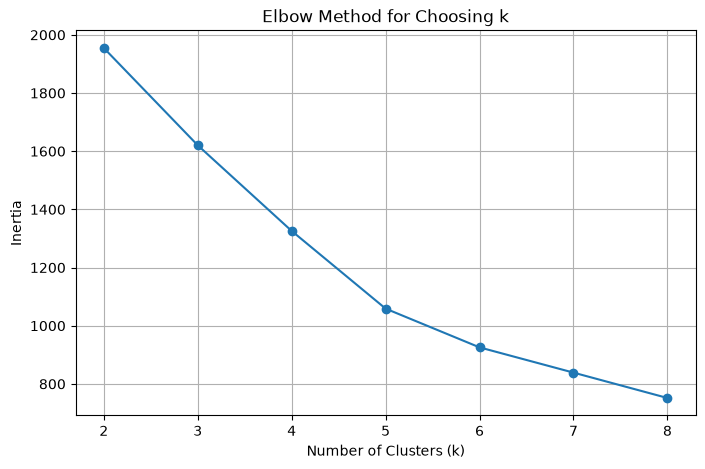

In [80]:
# Elbow plot

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 9),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Choosing k")
plt.xticks(range(2, 9))
plt.grid(True)

plt.show()

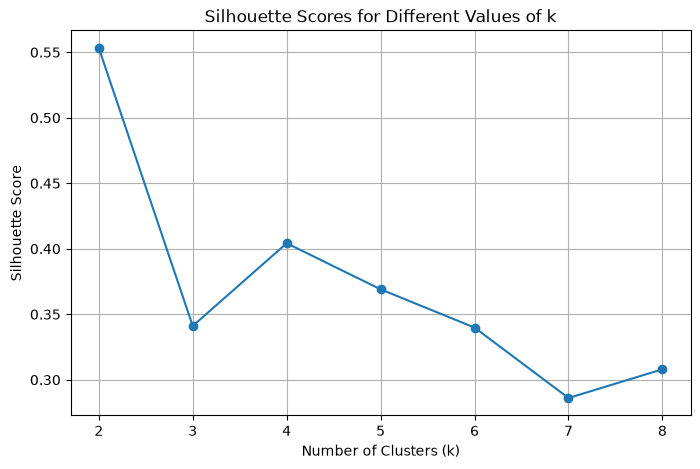

In [81]:
# Silhouette score plot

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 9),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Scores for Different Values of k")
plt.xticks(range(2, 9))
plt.grid(True)

plt.show()

A higher silhouette score is generally better because it means the observations within each cluster are relatively similar while the clusters are relatively well separated

### Selecting the Number of Clusters

The K-Means algorithm was tested with values of k ranging from 2 to 8. The inertia decreased as the number of clusters increased, which is expected because additional clusters reduce within-cluster variation. However, the silhouette scores provided stronger evidence for selecting the appropriate number of clusters. The highest silhouette score was obtained at k = 2, with a score of 0.553. The other values of k produced lower silhouette scores. Therefore, considering both the elbow/inertia analysis and the silhouette results, k = 2 was selected as the most suitable number of clusters for the Wholesale Customers dataset.

In [82]:
# Final K-Means model with k = 2

kmeans_final = KMeans(
    n_clusters=2,
    random_state=9386,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_scaled)

print("Cluster labels:")
print(cluster_labels[:20])

Cluster labels:
[1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1]


In [83]:
# Add cluster labels to the dataset

clustered_data = X.copy()

clustered_data["Cluster"] = cluster_labels

clustered_data.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster
0,12669,9656,7561,214,2674,1338,1
1,7057,9810,9568,1762,3293,1776,1
2,6353,8808,7684,2405,3516,7844,1
3,13265,1196,4221,6404,507,1788,1
4,22615,5410,7198,3915,1777,5185,1


In [84]:
# Check Number of customers in each cluster

cluster_counts = clustered_data["Cluster"].value_counts().sort_index()

print(cluster_counts)

Cluster
0     53
1    387
Name: count, dtype: int64


In [85]:
# Calculate mean spending for each cluster

cluster_means = clustered_data.groupby("Cluster")[features].mean()

cluster_means.round(2)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,11189.70,19090.26,26911.40,4202.17,11850.47,3564.43
1,12111.31,3975.64,5354.67,2917.14,1653.18,1245.55


### Cluster Profile Interpretation

The analysis produced two customer clusters. Cluster 0 contains 53 customers, while Cluster 1 contains 387 customers. Cluster 0 has higher average spending on Milk, Grocery, Detergents_Paper, Frozen, and Delicassen products. Its average spending on Grocery and Milk is particularly high. While, Cluster 1 has slightly higher average spending on Fresh products but lower spending across the other product categories. Therefore, Cluster 0 can be described as a smaller group of relatively high-spending customers, particularly for Milk, Grocery, and Detergents_Paper, while Cluster 1 represents the much larger group with lower spending across most categories.

In [87]:
# Apply PCA to reduce the data from 6 dimensions to 2 dimensions

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("PCA shape:", X_pca.shape)

print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("Total explained variance:",
      round(pca.explained_variance_ratio_.sum(), 3))

PCA shape: (440, 2)
Explained variance ratio:
[0.44082893 0.283764  ]
Total explained variance: 0.725


In [88]:
# Create a dataframe containing the PCA coordinates and cluster labels

pca_data = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": cluster_labels
})

pca_data.head()

,PC1,PC2,Cluster
0,0.193291,-0.305100,1
1,0.434420,-0.328413,1
2,0.811143,0.815096,1
3,-0.778648,0.652754,1
4,0.166287,1.271434,1


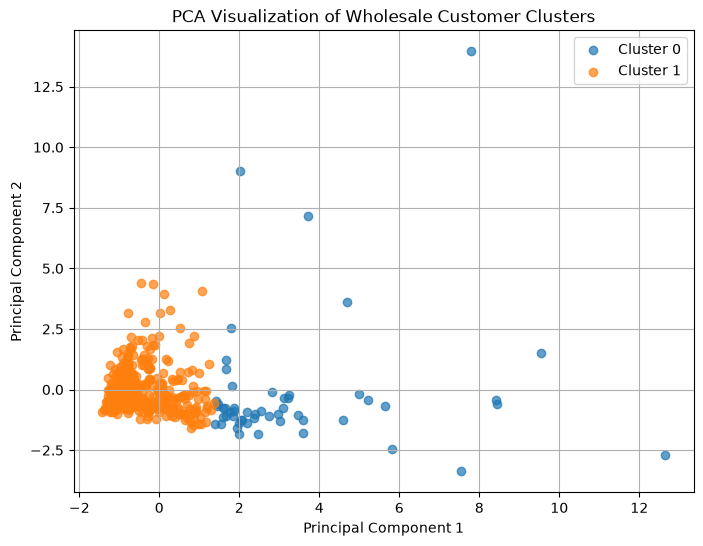

In [89]:
# PCA 2D visualization of the clusters

plt.figure(figsize=(8, 6))

for cluster in sorted(pca_data["Cluster"].unique()):
    cluster_points = pca_data[pca_data["Cluster"] == cluster]
    
    plt.scatter(
        cluster_points["PC1"],
        cluster_points["PC2"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Wholesale Customer Clusters")
plt.legend()
plt.grid(True)

plt.show()

### PCA Interpretation

The PCA transformation reduced the six standardized features to two principal components. The first principal component explains 44.1% of the total variance, while the second explains 28.4%. Together, the two components explain 72.5% of the variation in the dataset.

The PCA plot shows that Cluster 1 contains most of the customers and is concentrated mainly around the lower values of Principal Component 1. Cluster 0 is much smaller and is generally located further to the right, although there is some overlap between the two clusters. Several Cluster 0 observations are also positioned far from the main group, indicating customers with distinctive or relatively high spending patterns.

Overall, the PCA visualization provides reasonable separation between the two customer groups and supports the use of two clusters identified by the K-means analysis.

### PART D- Reflection and Report Quality

## Part D — Reflection

This assignment has improved my understanding of how different machine learning techniques are applied to real datasets. I learned the difference between supervised and unsupervised learning and how regression, classification, and clustering solve different types of problems. Through the practical work, I gained experience in exploratory data analysis, preprocessing, model training, evaluation, cross-validation, and visualization. I also learned that selecting a machine learning model should be based on its performance rather than simply choosing a more complex algorithm.

One challenge I encountered was obtaining poor performance from the Decision Tree Regressor on the Diabetes dataset. The model produced a negative R² score on the test set and also performed poorly during cross-validation. I addressed this by comparing its MAE, RMSE, and R² values with those of Linear Regression and using 5-fold cross-validation to evaluate generalization. Linear Regression performed better, so it was selected as the better model for this dataset. This showed me the importance of testing models carefully rather than assuming that a more complex model will always perform better.

An important consideration in machine learning is the potential for biased or unfair decisions. If a dataset contains biased or unrepresentative information, a model may produce unreliable results for certain groups. Therefore, models should be evaluated using appropriate metrics, and their results should not be used without considering their possible impact on people.

The assignment strengthened my practical machine learning skills and showed me the importance of reproducible analysis, clear visualizations and appropriate evaluation metrics.

I used AI tools to support my understanding of machine learning concepts, provide guidance on coding and help improve the organization and wording of my work.